# 02 · Características sin fuga y diseño del horizonte

**Problema de negocio:** cada noche se decide el rebalanceo para **mañana**. Eso fija qué información existe en el momento de pronosticar:

```
día D                                  medianoche          día D+1 (a pronosticar)
──────────────────────────────────────────┼───────────────────────────────────────
historia conocida (hasta las 23:00 de D)  │ 00:00 … 23:00  ← no se conoce nada de D+1
```

* **Modelo día siguiente (principal):** para la hora *t* de D+1 solo usa rezagos de **24 h o más** (`lag_24`, `lag_48`, `lag_168`, `lag_336`) y medias móviles calculadas sobre la serie desplazada 24 h. Todo lo que usa ocurrió, como muy tarde, a las 23:00 de D.
* **Modelo 1 hora (comparación):** usa además `lag_1`–`lag_3` y medias desde la hora anterior. Es un pronóstico a 1 hora vista: útil para operar durante el día, **no** para planificar la noche anterior.

Calendario (hora, día de semana, mes, feriado) y clima son comunes a los dos. El clima es el **real** observado, como sustituto de un pronóstico meteorológico a 24 h (limitación documentada).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda_citibike.config import PROCESADOS, REPORTES, FIGURAS

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#333333"
res = json.loads((REPORTES / "resultados.json").read_text(encoding="utf-8"))

In [2]:
from demanda_citibike.clima import cargar_clima
from demanda_citibike.features import FEATURES_DIA, FEATURES_1H, construir_caracteristicas, rezago_minimo

demanda = pd.read_parquet(PROCESADOS / "demanda_horaria.parquet")
df = construir_caracteristicas(demanda, cargar_clima())
print(f"Filas de modelado: {len(df):,} (se descartan las primeras 336 h de cada estación, sin historia suficiente)")
print(f"Desde {df['fecha_hora'].min()} hasta {df['fecha_hora'].max()}")
pd.DataFrame({
    "variable": FEATURES_DIA,
    "rezago_minimo_h": [rezago_minimo(c) for c in FEATURES_DIA],
})

Filas de modelado: 2,112,000 (se descartan las primeras 336 h de cada estación, sin historia suficiente)
Desde 2024-01-15 00:00:00 hasta 2024-12-31 23:00:00


,variable,rezago_minimo_h
0,lag_24,24
1,lag_48,48
2,lag_168,168
3,lag_336,336
4,media_24_d1,24
5,media_168_d1,24
6,temperatura_c,0
7,precipitacion_mm,0
8,lluvia_mm,0
9,viento_kmh,0


Ninguna variable del modelo día siguiente tiene un rezago mínimo entre 1 y 23 h (0 = calendario, clima o estación, que no dependen de la demanda pasada).

## Comprobación empírica de no fuga

Si cambio las salidas de las 24 h anteriores a una hora *t*, las variables del modelo día siguiente en *t* no deben moverse; las del modelo a 1 hora sí. (La misma prueba está automatizada en `tests/test_features.py`.)

In [3]:
est = df["estacion"].iloc[0]
t = pd.Timestamp("2024-10-16 18:00")
alterada = demanda.copy()
mask = (alterada["estacion"] == est) & (alterada["fecha_hora"] > t - pd.Timedelta(hours=24)) & (alterada["fecha_hora"] <= t)
alterada.loc[mask, "salidas"] += 100
sub_orig = demanda[demanda["estacion"] == est]
sub_alt = alterada[alterada["estacion"] == est]
f0 = construir_caracteristicas(sub_orig, cargar_clima())
f1 = construir_caracteristicas(sub_alt, cargar_clima())
a = f0[f0["fecha_hora"] == t].iloc[0]
b = f1[f1["fecha_hora"] == t].iloc[0]
cambian_dia = [c for c in FEATURES_DIA if a[c] != b[c]]
cambian_1h = [c for c in FEATURES_1H if a[c] != b[c]]
print("Variables del modelo día siguiente que cambian:", cambian_dia or "ninguna")
print("Variables del modelo 1 hora que cambian       :", cambian_1h)

Variables del modelo día siguiente que cambian: ninguna
Variables del modelo 1 hora que cambian       : ['lag_1', 'lag_2', 'lag_3', 'media_3', 'media_24', 'media_168']


## ¿Qué rezagos tienen señal?

Correlación entre la demanda de cada hora y la demanda *k* horas antes (promedio de las 250 estaciones).

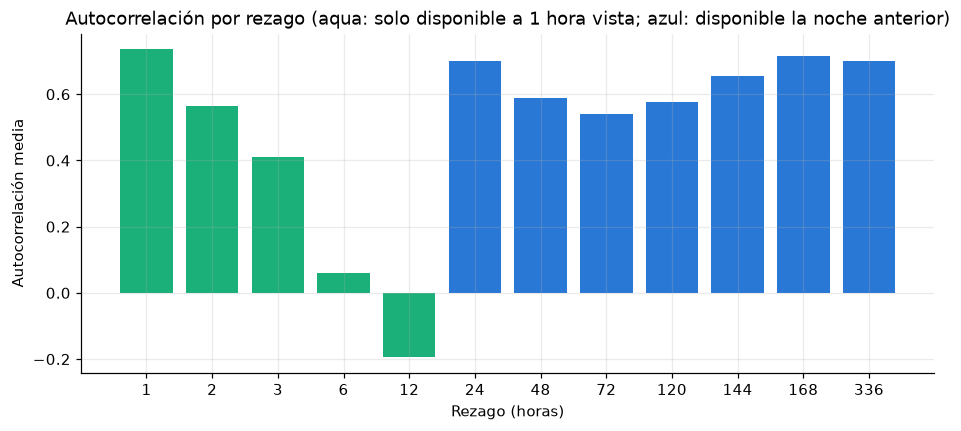

,1,2,3,6,12,24,48,72,120,144,168,336
autocorrelacion,0.736,0.564,0.41,0.061,-0.194,0.701,0.588,0.539,0.575,0.656,0.717,0.7


In [4]:
lags = [1, 2, 3, 6, 12, 24, 48, 72, 120, 144, 168, 336]
autocorr = []
for k in lags:
    c = df.groupby("estacion").apply(lambda g: g["salidas"].autocorr(k), include_groups=False).mean()
    autocorr.append(c)
fig, ax = plt.subplots(figsize=(10, 4))
colores = [AQUA if k < 24 else AZUL for k in lags]
ax.bar([str(k) for k in lags], autocorr, color=colores)
ax.set_xlabel("Rezago (horas)"); ax.set_ylabel("Autocorrelación media")
ax.set_title("Autocorrelación por rezago (aqua: solo disponible a 1 hora vista; azul: disponible la noche anterior)")
plt.show()
pd.Series(autocorr, index=lags, name="autocorrelacion").round(3).to_frame().T

La autocorrelación es máxima a 1 h, cae hacia 12 h y vuelve a subir en 24 h y, sobre todo, en 168 h (misma hora de la semana anterior). El modelo a 1 hora tiene acceso a la señal más fuerte; el de día siguiente debe apoyarse en los ciclos diario y semanal. Esa diferencia anticipa que el modelo a 1 hora tendrá menos error, pero no porque sea mejor modelo, sino porque responde a una pregunta más fácil.

## Clima y demanda (antes de modelar)

Salidas medias por hora (7–21 h, 250 estaciones): sin lluvia 3,154 · con lluvia 2,172 (-31 %)


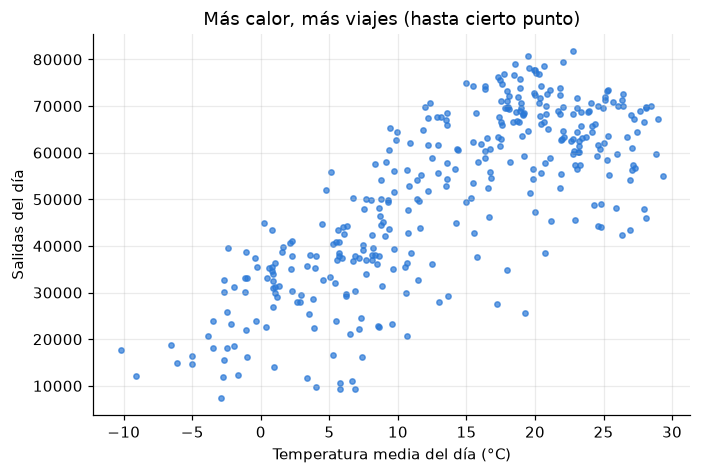

Correlación temperatura diaria – salidas: 0.77


In [5]:
horario = df.drop_duplicates("fecha_hora")[["fecha_hora", "temperatura_c", "lluvia_mm"]].set_index("fecha_hora")
total_h = df.groupby("fecha_hora")["salidas"].sum()
horario = horario.join(total_h)
horario["hora"] = horario.index.hour
horario["llueve"] = horario["lluvia_mm"] > 0
diurno = horario[horario["hora"].between(7, 21)]
comp = diurno.groupby("llueve")["salidas"].mean()
print(f"Salidas medias por hora (7–21 h, 250 estaciones): sin lluvia {comp[False]:,.0f} · con lluvia {comp[True]:,.0f} "
      f"({(comp[True] / comp[False] - 1) * 100:+.0f} %)")

d = df.groupby(df["fecha_hora"].dt.date).agg(salidas=("salidas", "sum"), temperatura=("temperatura_c", "mean"))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(d["temperatura"], d["salidas"], s=12, color=AZUL, alpha=0.7)
ax.set_xlabel("Temperatura media del día (°C)"); ax.set_ylabel("Salidas del día")
ax.set_title("Más calor, más viajes (hasta cierto punto)")
plt.show()
print(f"Correlación temperatura diaria – salidas: {d['temperatura'].corr(d['salidas']):.2f}")

En bruto, la lluvia reduce la demanda horaria y la temperatura está muy correlacionada con las salidas diarias. Pero parte de ese efecto ya lo capturan los rezagos (si ayer hizo frío, ayer también hubo pocas salidas). La pregunta correcta no es "¿el clima se correlaciona con la demanda?" sino **"¿el clima mejora el pronóstico una vez que el modelo ya tiene la historia?"**; se responde con la ablación del notebook 03.